# HW1 — Introduction and Learnability

**Course:** Statistical and Machine Learning  
**University:** Université de Haute-Alsace (UHA)  
**Student:** HAMDOUNI Thilelli  
**Program:** Master 2 — Mathematical Engineering and Data Science

## Introduction

In this homework, I will study the difference between PAC learning and Agnostic PAC learning using a simple threshold classifier.

I will first work with data without noise, where the labels are always correct. Then, I will add some noise to the labels to see how it affects the results.

For the experiments, I will use NumPy for the calculations and Matplotlib to create the graphs, without using machine learning libraries.

**Objective:** My goal is to understand how the number of training examples and the presence of noise affect the training error, the test error, and the probability that the model's error is higher than a chosen value.


Experiment Parameters

For this experiment, I chose the following parameters:

θ = 0.6: the threshold used to generate the labels.

ε = 0.10: the maximum error tolerance that I want to study.

δ = 0.05: the confidence parameter, corresponding to a 5% failure probability.

η = 0.15: the noise level, meaning that 15% of the labels are randomly changed.

I will repeat each experiment 500 times to get more reliable results. I will also use 10,000 independent test examples to evaluate the model's performance.

To make my experiments reproducible, I will use a fixed random seed.

In the PAC setting, I will compare the probability of having an error greater than ε with the chosen value of δ.

In the Agnostic PAC setting, the situation is different because some labels are incorrect. With 15% symmetric label noise, even the best classifier has an expected error of 15%. For this reason, instead of comparing the test error directly with ε = 0.10, I will also study the excess risk, which is the difference between the test error and the minimum possible error (η = 0.15).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

THETA = 0.60
EPSILON = 0.10
DELTA = 0.05
ETA = 0.15
SAMPLE_SIZES = [5, 10, 20, 50, 100, 200]
REPETITIONS = 500
TEST_SIZE = 10_000
SEED = 2026
rng = np.random.default_rng(SEED)


1. **Data Generation**

In this first part, I will generate random values of x between 0 and 1 using a uniform distribution.

Then, I will assign a label to each value based on the threshold θ = 0.6:

If x > 0.6, the label is 1.

Otherwise, the label is 0.

For the Agnostic PAC experiment, I will also introduce some noise by randomly changing each label with a probability of 15%.

This will allow me to compare the model's behavior with clean data and noisy data.

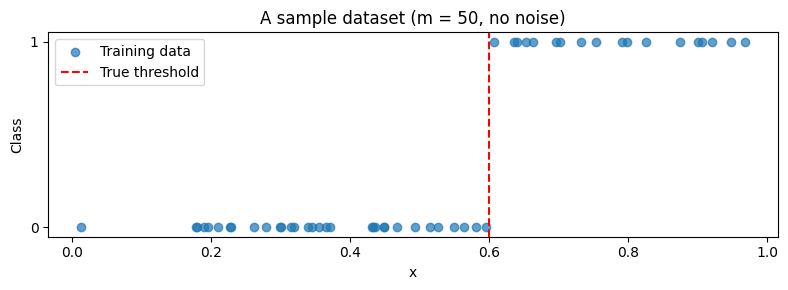

In [2]:
def target_labels(x, theta=THETA):
    return (x > theta).astype(int)


def generate_data(m, noise_rate=0.0, random_generator=rng):
    x = random_generator.uniform(0, 1, size=m)
    y = target_labels(x)
    flips = random_generator.random(m) < noise_rate
    y = np.where(flips, 1 - y, y)
    return x, y


x_demo, y_demo = generate_data(50)
plt.figure(figsize=(8, 3))
plt.scatter(x_demo, y_demo, alpha=0.7, label='Training data')
plt.axvline(THETA, color='red', linestyle='--', label='True threshold')
plt.xlabel('x')
plt.ylabel('Class')
plt.yticks([0, 1])
plt.title('A sample dataset (m = 50, no noise)')
plt.legend()
plt.tight_layout()
plt.show()

**Observation:**

In this graph, I can see that the red line separates the two classes correctly. The values on one side belong to class 0, while the values on the other side belong to class 1.

This result is expected because I generated the data without adding any noise.

## 2. Implementation of ERM

In this part, I will use the ERM (Empirical Risk Minimization) method to find the threshold that gives the smallest number of errors.

First, I sort the training data from the smallest to the largest value of x.

For each possible threshold, the model predicts:

- **0** for values on the left of the threshold.
- **1** for values on the right of the threshold.

To calculate the errors, I count:

- The points labeled 1 that are incorrectly predicted as 0.
- The points labeled 0 that are incorrectly predicted as 1.

I test all the possible positions of the threshold, including before the first point and after the last point.

Finally, I select a threshold that gives the lowest training error.

I implemented this method directly in Python, without using machine learning libraries like scikit-learn.

In [3]:
def predict(x, threshold):
    return (np.asarray(x) > threshold).astype(int)


def fit_erm(x, y):
    order = np.argsort(x)
    xs, ys = np.asarray(x)[order], np.asarray(y)[order]
    n = len(xs)

    left_ones = np.concatenate(([0], np.cumsum(ys)))
    total_zeros = np.sum(ys == 0)
    left_zeros = np.arange(n + 1) - left_ones
    right_zeros = total_zeros - left_zeros
    errors = left_ones + right_zeros

    # All m+1 possible positions between consecutive observations.
    candidates = np.concatenate(([0.0], (xs[:-1] + xs[1:]) / 2, [1.0]))
    best_index = np.argmin(errors)
    return float(candidates[best_index])


def classification_error(x, y, threshold):
    return np.mean(predict(x, threshold) != y)


# Simple test: with noiseless labels, ERM must fit every training point.
x_check, y_check = generate_data(100, noise_rate=0)
t_check = fit_erm(x_check, y_check)
assert classification_error(x_check, y_check, t_check) == 0
print('Estimated threshold:', round(t_check, 4))
print('Training error:', classification_error(x_check, y_check, t_check))

Estimated threshold: 0.5951
Training error: 0.0


3. Performance Evaluation

In this part, I will evaluate the performance of my model using different training sample sizes.

For each sample size, I generate two separate datasets:

Training data: used to find the best threshold with the ERM method.

Test data: 10,000 new examples used to check how well the model performs on unseen data.

Then, I calculate and compare two types of errors:

Training error: the percentage of incorrect predictions on the training data.

Test error: the percentage of incorrect predictions on the test data.

I will also compare the thresholds found by the model for each sample size.

The test data are not used during training. They are only used to evaluate the model.

My goal is to see if increasing the number of training examples helps the model make better predictions on new data.

m | threshold | train error | test error
  5 | 0.6379    | 0.0000      | 0.0364
 10 | 0.5982    | 0.0000      | 0.0012
 20 | 0.5998    | 0.0000      | 0.0001
 50 | 0.5989    | 0.0000      | 0.0011
100 | 0.5993    | 0.0000      | 0.0006
200 | 0.6049    | 0.0000      | 0.0051


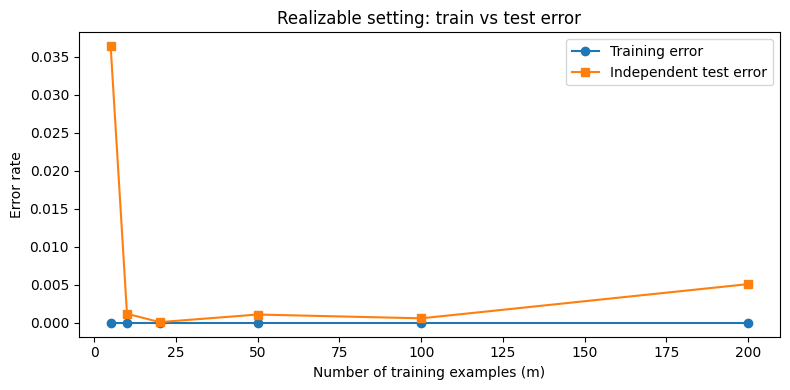

In [4]:
def single_evaluation(noise_rate=0.0):
    results = []
    for m in SAMPLE_SIZES:
        x_train, y_train = generate_data(m, noise_rate)
        x_test, y_test = generate_data(TEST_SIZE, noise_rate)
        t = fit_erm(x_train, y_train)
        results.append((m, t,
                        classification_error(x_train, y_train, t),
                        classification_error(x_test, y_test, t)))
    return np.array(results)


realizable_single = single_evaluation(0.0)
print('m | threshold | train error | test error')
for m, t, train_err, test_err in realizable_single:
    print(f'{int(m):3d} | {t:.4f}    | {train_err:.4f}      | {test_err:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(realizable_single[:, 0], realizable_single[:, 2], 'o-', label='Training error')
plt.plot(realizable_single[:, 0], realizable_single[:, 3], 's-', label='Independent test error')
plt.xlabel('Number of training examples (m)')
plt.ylabel('Error rate')
plt.title('Realizable setting: train vs test error')
plt.legend()
plt.tight_layout()
plt.show()

Interpretation:

In this experiment, I expect the training error to be 0 because the data have no noise and the model can find a threshold that correctly separates the two classes.

However, the test error can be different from 0 because the threshold found by the model is not always exactly equal to the real threshold (θ = 0.6).

When I increase the number of training examples, the model generally estimates the threshold more accurately, which helps reduce the test error.

However, the results may not improve at every step because the data are generated randomly. For this reason, a larger training set does not always give a lower test error in a single experiment.

## 4. Experimental Verification of PAC Learning

In this part, I will study how the number of training examples affects the performance of my model in the PAC learning setting.

For each sample size (m = 5, 10, 20, 50, 100 and 200), I repeat the experiment 500 times to obtain more reliable results.

For each repetition, I generate new training and test data, train the model and calculate the test error.

Then, I calculate the percentage of experiments where the test error is greater than ε = 0.10.

On the graph, I use a horizontal line at δ = 0.05 (5%) as a reference to compare the results.

My goal is to see if the probability of having a test error greater than 10% decreases when I increase the number of training examples.

These experiments help me understand PAC learning in practice, but they do not provide a mathematical proof of the PAC theorem.

m | mean train | mean test | P(test error > epsilon)
  5 | 0.0000     | 0.1076    | 0.356
 10 | 0.0000     | 0.0491    | 0.120
 20 | 0.0000     | 0.0223    | 0.004
 50 | 0.0000     | 0.0092    | 0.000
100 | 0.0000     | 0.0054    | 0.000
200 | 0.0000     | 0.0026    | 0.000


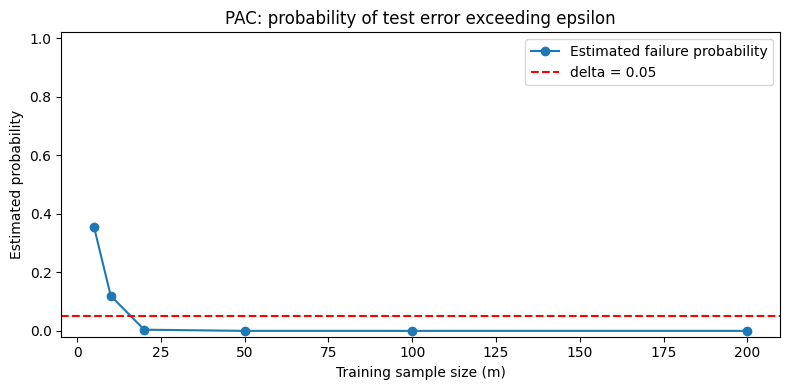

In [5]:
def repeated_evaluation(noise_rate):
    mean_train, mean_test, failure_prob, excess_failure = [], [], [], []
    for m in SAMPLE_SIZES:
        train_errors, test_errors = [], []
        for _ in range(REPETITIONS):
            x_train, y_train = generate_data(m, noise_rate)
            x_test, y_test = generate_data(TEST_SIZE, noise_rate)
            t = fit_erm(x_train, y_train)
            train_errors.append(classification_error(x_train, y_train, t))
            test_errors.append(classification_error(x_test, y_test, t))
        train_errors = np.asarray(train_errors)
        test_errors = np.asarray(test_errors)
        mean_train.append(train_errors.mean())
        mean_test.append(test_errors.mean())
        failure_prob.append(np.mean(test_errors > EPSILON))
        # For symmetric independent label flips (eta<0.5), best-in-class risk is eta.
        excess_failure.append(np.mean(test_errors - noise_rate > EPSILON))
    return { 'mean_train': np.array(mean_train),
             'mean_test': np.array(mean_test),
             'failure': np.array(failure_prob),
             'excess_failure': np.array(excess_failure) }


realizable = repeated_evaluation(0.0)
print('m | mean train | mean test | P(test error > epsilon)')
for i, m in enumerate(SAMPLE_SIZES):
    print(f'{m:3d} | {realizable["mean_train"][i]:.4f}     | '
          f'{realizable["mean_test"][i]:.4f}    | {realizable["failure"][i]:.3f}')

plt.figure(figsize=(8, 4))
plt.plot(SAMPLE_SIZES, realizable['failure'], 'o-', label='Estimated failure probability')
plt.axhline(DELTA, color='red', linestyle='--', label='delta = 0.05')
plt.xlabel('Training sample size (m)')
plt.ylabel('Estimated probability')
plt.ylim(-0.02, 1.02)
plt.title('PAC: probability of test error exceeding epsilon')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:**

From my results, I can see that the failure probability decreases as the number of training examples increases.

For m = 5, the failure probability is 35.6%, while for m = 20, it decreases to 0.4%. For m = 200, I observed no failures among the 500 repetitions.

I also notice that the estimated failure probability becomes lower than δ = 0.05 from m = 20.

These results show that using more training examples generally makes the model more reliable.

## 5. From PAC to Agnostic PAC

In this part, I will repeat the previous experiments, but this time I will add 15% noise to the labels.

This means that each label has a 15% chance of being changed from 0 to 1 or from 1 to 0.

Because of this noise, even the best threshold cannot completely eliminate the prediction errors.

To better understand the impact of noise, I will compare two types of errors:

- **Test error:** the total percentage of incorrect predictions.
- **Excess error:** the difference between the test error and the minimum possible error (η = 0.15).

My goal is to see how the model performs with noisy data and whether increasing the number of training examples still helps improve its performance.

NOISY SETTING: one dataset per sample size
m | threshold | train error | test error
  5 | 0.5548    | 0.0000      | 0.1766
 10 | 0.6807    | 0.1000      | 0.2109
 20 | 0.6114    | 0.1500      | 0.1619
 50 | 0.6262    | 0.1600      | 0.1714
100 | 0.5998    | 0.1700      | 0.1516
200 | 0.5977    | 0.2000      | 0.1479

500 repetitions: comparison
m | PAC mean test | agnostic mean test | P(noisy excess error > epsilon)
  5 | 0.1076        | 0.2862             | 0.472
 10 | 0.0491        | 0.2366             | 0.300
 20 | 0.0223        | 0.2036             | 0.168
 50 | 0.0092        | 0.1688             | 0.014
100 | 0.0054        | 0.1587             | 0.000
200 | 0.0026        | 0.1554             | 0.000


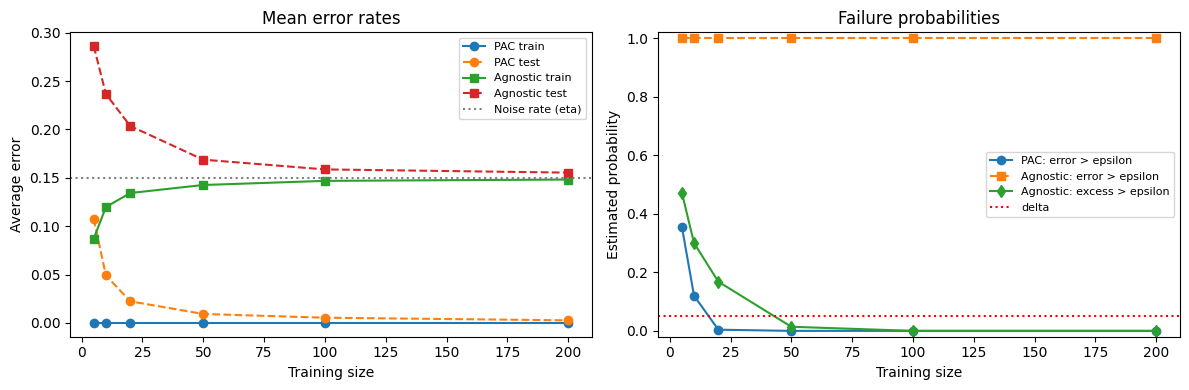

In [6]:
noisy_single = single_evaluation(ETA)
agnostic = repeated_evaluation(ETA)

print('NOISY SETTING: one dataset per sample size')
print('m | threshold | train error | test error')
for m, t, train_err, test_err in noisy_single:
    print(f'{int(m):3d} | {t:.4f}    | {train_err:.4f}      | {test_err:.4f}')

print('\n500 repetitions: comparison')
print('m | PAC mean test | agnostic mean test | P(noisy excess error > epsilon)')
for i, m in enumerate(SAMPLE_SIZES):
    print(f'{m:3d} | {realizable["mean_test"][i]:.4f}        | '
          f'{agnostic["mean_test"][i]:.4f}             | '
          f'{agnostic["excess_failure"][i]:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(SAMPLE_SIZES, realizable['mean_train'], 'o-', label='PAC train')
axes[0].plot(SAMPLE_SIZES, realizable['mean_test'], 'o--', label='PAC test')
axes[0].plot(SAMPLE_SIZES, agnostic['mean_train'], 's-', label='Agnostic train')
axes[0].plot(SAMPLE_SIZES, agnostic['mean_test'], 's--', label='Agnostic test')
axes[0].axhline(ETA, color='gray', linestyle=':', label='Noise rate (eta)')
axes[0].set(xlabel='Training size', ylabel='Average error', title='Mean error rates')
axes[0].legend(fontsize=8)
axes[1].plot(SAMPLE_SIZES, realizable['failure'], 'o-', label='PAC: error > epsilon')
axes[1].plot(SAMPLE_SIZES, agnostic['failure'], 's--', label='Agnostic: error > epsilon')
axes[1].plot(SAMPLE_SIZES, agnostic['excess_failure'], 'd-', label='Agnostic: excess > epsilon')
axes[1].axhline(DELTA, color='red', linestyle=':', label='delta')
axes[1].set(xlabel='Training size', ylabel='Estimated probability',
            title='Failure probabilities', ylim=(-0.02, 1.02))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Observation:**

In the Agnostic PAC experiment, I observed that the average test error decreases from 28.62% for m = 5 to 15.54% for m = 200.

This shows that the model improves when I use more training examples, even with noisy labels.

However, the error remains close to 15% because of the label noise. The model can learn a better threshold, but it cannot completely remove the noise.

### Discussion Questions

**1. Can the empirical error still reach zero?**

Yes, it is still possible, especially when the training dataset is small. For example, if no labels are changed by the noise, the model can still find a threshold with zero training error.

However, when the number of training examples increases, there is a higher chance of having noisy labels that cannot be correctly separated by a single threshold.

So, unlike the PAC setting, a training error of zero is no longer guaranteed.

**2. Does increasing the number of training examples still improve generalization?**

Yes, increasing the number of training examples generally helps the model find a better threshold.

However, because the data contain noise, the test error cannot completely disappear. Instead, it should get closer to the minimum possible error of 15%.

I also expect some small variations between experiments because the data are randomly generated.

This shows that having more data can improve the model's performance, even when some labels are incorrect.

**3. What is the difference between PAC and Agnostic PAC learning?**

The main difference is the presence of errors in the data.

In the PAC setting, the labels are correct and the true classification rule belongs to the hypothesis class. This means that a classifier with zero theoretical error exists.

In the Agnostic PAC setting, some labels can be incorrect, so the model cannot always classify all the examples correctly.

The objective of ERM is therefore to find a classifier whose error is as close as possible to the best achievable error.

In my experiment, with 15% symmetric noise, the optimal threshold is still θ = 0.6, but the minimum possible error is 15% instead of 0%.

## Conclusion

In this homework, I studied the difference between PAC learning and Agnostic PAC learning using a threshold classifier and the ERM method.

In the first experiment, without noise, the model was able to classify all the training examples correctly. I also found that increasing the number of training examples generally helps reduce the test error and the probability of having an error greater than 10%.

In the second experiment, I added 15% noise to the labels. I found that the model can still improve with more training examples, but the test error cannot completely disappear because of the noise. Instead, it tends to get closer to 15%, which is the minimum possible error in this case.

These experiments helped me understand that more training data can improve the model's ability to make predictions, but the quality of the data is also important.

Overall, I learned that in the realizable PAC setting, the goal is to obtain a small classification error, while in the Agnostic PAC setting, the goal is to get as close as possible to the best achievable error.

Looking at my experimental results, I observed that the PAC failure probability decreased from 35.6% with 5 training examples to 0% observed failures with 200 examples. It became lower than the chosen value δ = 0.05 from m = 20.

In the Agnostic PAC experiment, the average test error decreased from 28.62% to 15.54%.

These results helped me understand that increasing the number of training examples improves generalization, but the presence of noise limits the best possible performance.